# CartPole-v1: Deep Q-Network (Assignment 2a), baseline run

Standard DQN with a replay buffer and a target network (hard copy every 500 steps), gamma = 0.95, CPU only. Run all cells; results are saved to `OUT`.

In [1]:
!pwd


/nfs/home/kij6504


In [2]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:           125Gi       2.5Gi        15Gi       2.0Mi       107Gi       121Gi
Swap:             0B          0B          0B


In [4]:
!nvidia-smi

Mon Nov  9 21:01:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1080        On  |   00000000:05:00.0 Off |                  N/A |
|  0%   27C    P8              7W /  198W |       3MiB /   8192MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
%pip install "gymnasium[atari]>=1.1" "ale-py>=0.10" torch matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
GPU_INDEX = "0"                                
os.environ.setdefault("CUDA_VISIBLE_DEVICES", GPU_INDEX)

import json, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import gymnasium as gym

DEVICE = torch.device("cpu") 
print(f"gymnasium {gym.__version__} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
torch.set_num_threads(4)

BLUE, ORANGE, GRAY, AQUA = "#2a78d6", "#eb6834", "#52514e", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

OUT = "./rl_hw2_cartpole"
os.makedirs(OUT, exist_ok=True)
print("Results folder:", os.path.abspath(OUT))

gymnasium 1.4.0 | torch 2.14.0+cu126 | device cpu
Results folder: /nfs/home/kij6504/rl_hw2_cartpole


## Settings

Defaults used by `train()`. `Q_CEILING = 1/(1 - gamma) = 20` is the value of balancing forever.

In [4]:
GAMMA = 0.95
LR = 1e-3
HIDDEN = 128
BUFFER_SIZE = 50_000
BATCH_SIZE = 64
WARMUP_STEPS = 1_000
TARGET_SYNC = 500
TRAIN_EVERY = 1
EPS_START, EPS_END, EPS_DECAY_STEPS = 1.0, 0.02, 10_000
GRAD_CLIP = 10.0
N_EPISODES = 800
STOP_WHEN_SOLVED = True
SOLVED_AVG = 475.0
SEEDS = [0, 1, 2]
EVAL_EPISODES = 500
MAX_STEPS = 500                       # CartPole-v1 cuts every episode at 500 steps
SNAPSHOT_EVERY = 25                   # snapshot interval (episodes)
Q_CEILING = 1.0 / (1.0 - GAMMA)       # = 20
print(f"Q ceiling 1/(1-gamma) = {Q_CEILING:.1f}")

Q ceiling 1/(1-gamma) = 20.0


## Random baseline

In [5]:
env = gym.make("CartPole-v1")
print("State:", env.observation_space, "\n -> [cart position, cart speed, pole angle, pole angular speed]")
print("Actions:", env.action_space, "-> 0 = push left, 1 = push right")
rng = np.random.default_rng(0)
random_scores = []
for ep in range(200):
    env.reset(seed=10_000 + ep)
    total, done = 0, False
    while not done:
        _, r, term, trunc, _ = env.step(int(rng.integers(2)))
        total += r; done = term or trunc
    random_scores.append(total)
env.close()
print(f"Random play over 200 episodes: mean {np.mean(random_scores):.1f}, std {np.std(random_scores):.1f}")

State: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) 
 -> [cart position, cart speed, pole angle, pole angular speed]
Actions: Discrete(2) -> 0 = push left, 1 = push right
Random play over 200 episodes: mean 21.6, std 10.8


## Q-network, replay buffer, epsilon-greedy

In [6]:
class QNet(nn.Module):
    """state -> one Q-value per action"""
    def __init__(self, obs_dim=4, n_actions=2, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(obs_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, n_actions))

    def forward(self, x):
        return self.net(x)


class ReplayBuffer:
    """Fixed-size circular store of (s, a, r, s', done). The oldest transition is overwritten first."""
    def __init__(self, capacity, obs_dim):
        self.s = np.zeros((capacity, obs_dim), np.float32)
        self.a = np.zeros(capacity, np.int64)
        self.r = np.zeros(capacity, np.float32)
        self.s2 = np.zeros((capacity, obs_dim), np.float32)
        self.done = np.zeros(capacity, np.float32)
        self.capacity, self.ptr, self.size = capacity, 0, 0

    def add(self, s, a, r, s2, done):
        i = self.ptr
        self.s[i], self.a[i], self.r[i], self.s2[i], self.done[i] = s, a, r, s2, float(done)
        self.ptr = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, rng):
        idx = rng.integers(0, self.size, size=batch_size)
        return (torch.from_numpy(self.s[idx]), torch.from_numpy(self.a[idx]), torch.from_numpy(self.r[idx]),
                torch.from_numpy(self.s2[idx]), torch.from_numpy(self.done[idx]))

    def __len__(self):
        return self.size


def epsilon_at(step, start=EPS_START, end=EPS_END, decay_steps=EPS_DECAY_STEPS):
    frac = min(1.0, step / decay_steps)
    return start + frac * (end - start)


@torch.no_grad()
def q_of(net, s):
    """Q-values of one state, as a numpy array."""
    return net(torch.as_tensor(s, dtype=torch.float32, device=DEVICE).unsqueeze(0))[0].cpu().numpy()


def choose_action(q, eps, n_actions, rng):
    if rng.random() < eps:
        return int(rng.integers(n_actions))
    return int(np.argmax(q))


print(QNet())
b = ReplayBuffer(3, 4)
for i in range(5):
    b.add(np.full(4, i), i % 2, 1.0, np.full(4, i + 1), i == 4)
print("Circular buffer after 5 adds with capacity 3 holds steps", sorted(b.s[:, 0].astype(int)), "(expected [2, 3, 4])")
print("epsilon at steps 0 / 5000 / 10000 / 50000:", [round(epsilon_at(t), 3) for t in (0, 5000, 10000, 50000)])

QNet(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Circular buffer after 5 adds with capacity 3 holds steps [np.int64(2), np.int64(3), np.int64(4)] (expected [2, 3, 4])
epsilon at steps 0 / 5000 / 10000 / 50000: [1.0, 0.51, 0.02, 0.02]


## DQN update

Target: y = r + gamma * (1 - done) * max_a Q_target(s', a), Huber loss on the action taken.

In [7]:
def dqn_update(online, target, opt, batch, gamma, loss_fn="huber", grad_clip=GRAD_CLIP):
    s, a, r, s2, done = (x.to(DEVICE) for x in batch)
    q_sa = online(s).gather(1, a.unsqueeze(1)).squeeze(1)         # Q(s, a) of the action taken
    with torch.no_grad():
        q_next = target(s2).max(dim=1).values
        y = r + gamma * (1.0 - done) * q_next                      # done -> y = r
    loss = F.smooth_l1_loss(q_sa, y) if loss_fn == "huber" else F.mse_loss(q_sa, y)
    opt.zero_grad()
    loss.backward()
    if grad_clip:
        nn.utils.clip_grad_norm_(online.parameters(), grad_clip)
    opt.step()
    return loss.item(), (y - q_sa).abs().mean().item()


def sync_target(online, target, tau=1.0):
    """tau = 1: hard copy (classic DQN). tau < 1: Polyak averaging (soft update)."""
    with torch.no_grad():
        for p_t, p_o in zip(target.parameters(), online.parameters()):
            p_t.mul_(1.0 - tau).add_(tau * p_o)

### Check 2: update sanity check

After one update the target network is unchanged, the online network has changed, and terminal transitions give y = r.

In [8]:
torch.manual_seed(0)
online, target = QNet().to(DEVICE), QNet().to(DEVICE); sync_target(online, target)
opt = torch.optim.Adam(online.parameters(), lr=LR)
s_ = torch.randn(8, 4); a_ = torch.randint(0, 2, (8,)); r_ = torch.ones(8); s2_ = torch.randn(8, 4); d_ = torch.ones(8)
before_t = [p.clone() for p in target.parameters()]; before_o = [p.clone() for p in online.parameters()]
dqn_update(online, target, opt, (s_, a_, r_, s2_, d_), GAMMA)
print("target network unchanged:", all(torch.equal(p, q) for p, q in zip(before_t, target.parameters())))
print("online network changed:  ", any(not torch.equal(p, q) for p, q in zip(before_o, online.parameters())))
with torch.no_grad():
    y_ = r_.to(DEVICE) + GAMMA * (1 - d_.to(DEVICE)) * target(s2_.to(DEVICE)).max(1).values
print("all transitions done -> every target equals r = 1:", bool(torch.allclose(y_, torch.ones_like(y_))))

target network unchanged: True
online network changed:   True
all transitions done -> every target equals r = 1: True


## Training loop

Only `terminated` is stored as done, so the 500-step cut-off still bootstraps. Per episode: reward, max-Q (episode mean and max), loss, epsilon. Keeps the best-average checkpoint and a snapshot every `SNAPSHOT_EVERY` episodes.

In [9]:
def train(seed, tag="dqn", make_env=lambda: gym.make("CartPole-v1"), obs_dim=4, n_actions=2,
          gamma=GAMMA, lr=LR, buffer_size=BUFFER_SIZE, batch_size=BATCH_SIZE, warmup=WARMUP_STEPS,
          target_sync=TARGET_SYNC, tau=1.0, train_every=TRAIN_EVERY, n_episodes=N_EPISODES,
          eps_schedule=epsilon_at, loss_fn="huber", handle_truncation=True,
          stop_when_solved=STOP_WHEN_SOLVED, solved_avg=SOLVED_AVG, snapshot_every=SNAPSHOT_EVERY,
          verbose=True, save=True):
    torch.manual_seed(seed); np.random.seed(seed)
    rng = np.random.default_rng(seed)
    env = make_env()
    online = QNet(obs_dim, n_actions).to(DEVICE)
    target = QNet(obs_dim, n_actions).to(DEVICE)
    sync_target(online, target, 1.0)                               # start identical
    opt = torch.optim.Adam(online.parameters(), lr=lr)
    buf = ReplayBuffer(buffer_size, obs_dim)
    hist = {k: [] for k in ["reward", "max_q", "peak_q", "loss", "td_err", "eps", "length", "truncated"]}
    snapshots = {}
    best_ma, best_state = -1.0, None
    step, ep_seed, t0 = 0, seed * 100_000, time.time()
    ep, ma, eps, truncated = 0, 0.0, eps_schedule(0), False

    for ep in range(1, n_episodes + 1):
        s, _ = env.reset(seed=ep_seed); ep_seed += 1
        ep_r, ep_maxq, ep_loss, ep_td = 0.0, [], [], []
        while True:
            eps = eps_schedule(step)
            q = q_of(online, s)
            ep_maxq.append(float(q.max()))
            a = choose_action(q, eps, n_actions, rng)
            s2, r, terminated, truncated, _ = env.step(a)
            done_for_target = terminated if handle_truncation else (terminated or truncated)
            buf.add(s, a, r, s2, done_for_target)
            s, ep_r, step = s2, ep_r + r, step + 1
            if len(buf) >= warmup and step % train_every == 0:
                loss, td = dqn_update(online, target, opt, buf.sample(batch_size, rng), gamma, loss_fn)
                ep_loss.append(loss); ep_td.append(td)
            if step % target_sync == 0:
                sync_target(online, target, tau)
            if terminated or truncated:
                break
        hist["reward"].append(ep_r)
        hist["max_q"].append(float(np.mean(ep_maxq))); hist["peak_q"].append(float(np.max(ep_maxq)))
        hist["loss"].append(float(np.mean(ep_loss)) if ep_loss else float("nan"))
        hist["td_err"].append(float(np.mean(ep_td)) if ep_td else float("nan"))
        hist["eps"].append(float(eps)); hist["length"].append(len(ep_maxq))
        hist["truncated"].append(bool(truncated and not terminated))
        ma = float(np.mean(hist["reward"][-100:]))
        if ep >= 100 and ma > best_ma:
            best_ma, best_state = ma, copy.deepcopy(online.state_dict())
        if snapshot_every and (ep % snapshot_every == 0 or ep == 1):
            snapshots[ep] = {k: v.detach().cpu().clone() for k, v in online.state_dict().items()}
        if verbose and ep % 50 == 0:
            print(f"  [{tag}, seed {seed}] episode {ep:4d} | last-100 avg {ma:6.1f} | mean max-Q {hist['max_q'][-1]:5.2f} "
                  f"| eps {eps:.2f} | steps {step:6d} | {time.time() - t0:4.0f}s")
        if stop_when_solved and ep >= 100 and ma >= solved_avg:
            if verbose:
                print(f"  [{tag}, seed {seed}] solved at episode {ep}: last-100 avg {ma:.1f} >= {solved_avg} ({time.time() - t0:.0f}s)")
            break
    env.close()
    if best_state is None:
        best_ma, best_state = ma, copy.deepcopy(online.state_dict())
    snapshots[ep] = {k: v.detach().cpu().clone() for k, v in online.state_dict().items()}
    if save:
        torch.save(online.state_dict(), os.path.join(OUT, f"qnet_{tag}_seed{seed}.pt"))
        torch.save(best_state, os.path.join(OUT, f"qnet_best_{tag}_seed{seed}.pt"))
        with open(os.path.join(OUT, f"history_{tag}_seed{seed}.json"), "w") as f:
            json.dump(hist, f)
    return {"hist": hist, "online": online, "target": target, "buffer": buf, "best_state": best_state,
            "best_ma": best_ma, "snapshots": snapshots, "episodes": ep, "steps": step}

### Check 3: first 10 transitions

Untrained network with random actions: Q is close to 0, so every target is close to 1.

In [10]:
def trace_first_steps(n=10, seed=7):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")
    online, target = QNet().to(DEVICE), QNet().to(DEVICE); sync_target(online, target)
    s, _ = env.reset(seed=seed)
    print(" t | state [x, xdot, theta, thetadot]      | Q(s,L)  Q(s,R) | a | r | done | max Q_tgt(s') | target y")
    for t in range(n):
        q = q_of(online, s)
        a = choose_action(q, 1.0, 2, rng)
        s2, r, term, trunc, _ = env.step(a)
        qn = float(q_of(target, s2).max())
        y = r + GAMMA * (0.0 if term else qn)
        print(f"{t:2d} | {np.array2string(s, precision=3, suppress_small=True, floatmode='fixed'):37s} "
              f"| {q[0]:6.3f} {q[1]:6.3f} | {a} | {r:.0f} |  {int(term)}   | {qn:13.3f} | {y:7.3f}")
        s = s2
        if term or trunc:
            print("   (episode ended, environment reset)"); s, _ = env.reset(seed=seed + t + 1)
    env.close()


trace_first_steps()

 t | state [x, xdot, theta, thetadot]      | Q(s,L)  Q(s,R) | a | r | done | max Q_tgt(s') | target y
 0 | [ 0.013  0.040  0.028 -0.027]         |  0.085  0.005 | 1 | 1 |  0   |         0.081 |   1.077
 1 | [ 0.013  0.234  0.027 -0.311]         |  0.081  0.006 | 1 | 1 |  0   |         0.086 |   1.082
 2 | [ 0.018  0.429  0.021 -0.595]         |  0.086  0.013 | 0 | 1 |  0   |         0.083 |   1.079
 3 | [ 0.027  0.234  0.009 -0.296]         |  0.083  0.008 | 0 | 1 |  0   |         0.089 |   1.085
 4 | [ 0.031  0.039  0.003 -0.001]         |  0.089  0.007 | 0 | 1 |  0   |         0.096 |   1.091
 5 | [ 0.032 -0.157  0.003  0.293]         |  0.096  0.007 | 1 | 1 |  0   |         0.089 |   1.084
 6 | [0.029 0.038 0.009 0.001]             |  0.089  0.007 | 1 | 1 |  0   |         0.083 |   1.079
 7 | [ 0.030  0.233  0.009 -0.289]         |  0.083  0.008 | 0 | 1 |  0   |         0.090 |   1.085
 8 | [0.034 0.038 0.003 0.007]             |  0.090  0.008 | 1 | 1 |  0   |         0.084 |   1.08

### Smoke test

In [11]:
_smoke = train(seed=99, tag="smoke", n_episodes=5, warmup=50, verbose=False, save=False, snapshot_every=0)
print("smoke run ok:", len(_smoke["hist"]["reward"]), "episodes,", _smoke["steps"], "steps, last loss",
      round(_smoke["hist"]["loss"][-1], 4))

smoke run ok: 5 episodes, 115 steps, last loss 0.0034


## Training (3 seeds)

In [13]:
results = {}
for seed in SEEDS:
    print(f"Training DQN, seed {seed}")
    results[seed] = train(seed)
print("\nseed | episodes trained | best 100-episode average | env steps")
for seed in SEEDS:
    print(f"{seed:4d} | {results[seed]['episodes']:16d} | {results[seed]['best_ma']:24.1f} | {results[seed]['steps']:9d}")

Training DQN, seed 0
  [dqn, seed 0] episode   50 | last-100 avg   24.7 | mean max-Q  1.06 | eps 0.88 | steps   1233 |    1s
  [dqn, seed 0] episode  100 | last-100 avg   22.0 | mean max-Q  2.72 | eps 0.78 | steps   2196 |    2s
  [dqn, seed 0] episode  150 | last-100 avg   24.9 | mean max-Q  5.38 | eps 0.64 | steps   3722 |    5s
  [dqn, seed 0] episode  200 | last-100 avg   70.6 | mean max-Q 11.66 | eps 0.09 | steps   9257 |   16s
  [dqn, seed 0] episode  250 | last-100 avg  113.3 | mean max-Q 14.94 | eps 0.02 | steps  15052 |   27s
  [dqn, seed 0] episode  300 | last-100 avg  128.6 | mean max-Q 17.35 | eps 0.02 | steps  22112 |   41s
  [dqn, seed 0] episode  350 | last-100 avg  137.1 | mean max-Q 18.92 | eps 0.02 | steps  28762 |   53s
  [dqn, seed 0] episode  400 | last-100 avg  126.4 | mean max-Q 18.99 | eps 0.02 | steps  34748 |   65s
  [dqn, seed 0] episode  450 | last-100 avg  123.1 | mean max-Q 18.92 | eps 0.02 | steps  41073 |   77s
  [dqn, seed 0] episode  500 | last-100 avg

## Plot (i): max Q-value per episode

Dashed line: 1/(1 - gamma) = 20.

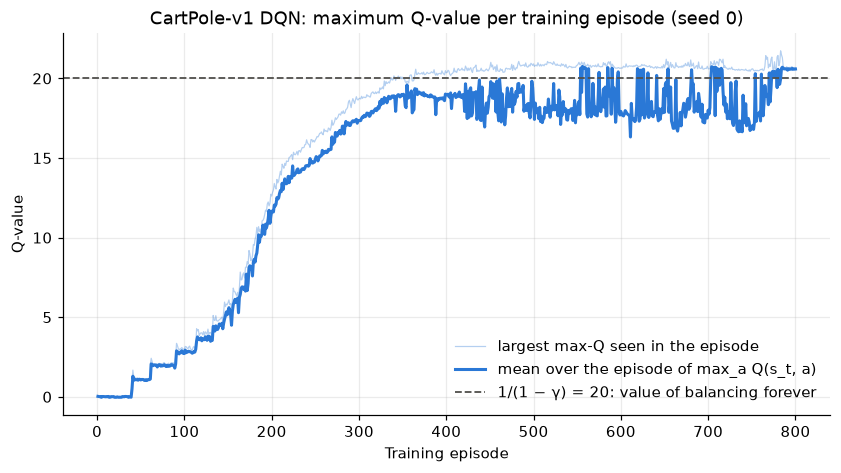

In [14]:
def moving_average(x, w=100):
    x = np.asarray(x, dtype=float)
    c = np.concatenate([[0.0], np.cumsum(x)])
    i = np.arange(len(x)); lo = np.maximum(0, i - w + 1)
    return (c[i + 1] - c[lo]) / (i + 1 - lo)


def plot_max_q(hist, title, save_path=None, ceiling=Q_CEILING):
    ep = np.arange(1, len(hist["max_q"]) + 1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(ep, hist["peak_q"], color=BLUE, lw=0.8, alpha=0.35, label="largest max-Q seen in the episode")
    ax.plot(ep, hist["max_q"], color=BLUE, lw=2, label="mean over the episode of max_a Q(s_t, a)")
    if ceiling:
        ax.axhline(ceiling, color=GRAY, ls="--", lw=1.2, label=f"1/(1 − γ) = {ceiling:.0f}: value of balancing forever")
    ax.set_xlabel("Training episode"); ax.set_ylabel("Q-value"); ax.set_title(title)
    ax.legend(loc="lower right", frameon=False)
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_training(rewards, title, save_path=None, ylim=(0, 520), ylabel="Episode reward (steps balanced)"):
    ep = np.arange(1, len(rewards) + 1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(ep, rewards, color=BLUE, lw=0.8, alpha=0.35, label="Episode reward")
    ax.plot(ep, moving_average(rewards), color=BLUE, lw=2, label="Moving average (100 episodes)")
    ax.set_xlabel("Training episode"); ax.set_ylabel(ylabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_title(title); ax.legend(loc="upper left", frameon=False)
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_max_q(results[0]["hist"], "CartPole-v1 DQN: maximum Q-value per training episode (seed 0)",
           os.path.join(OUT, "max_q_seed0.png"))

## Plot (ii): episode reward and 100-episode moving average

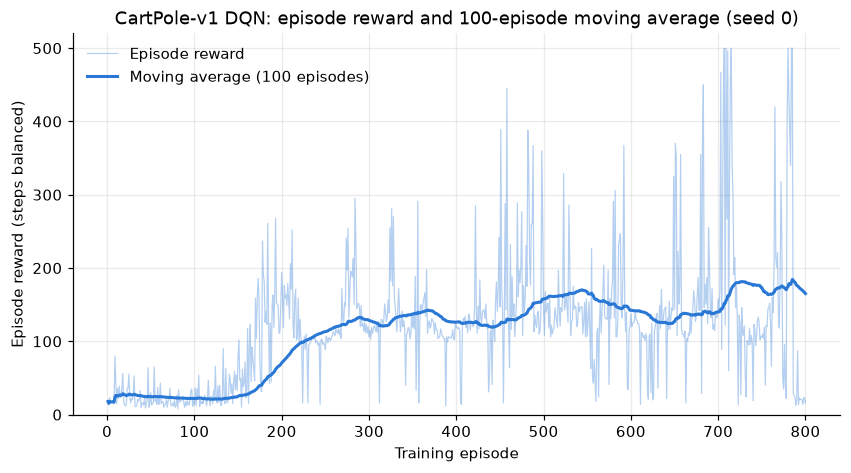

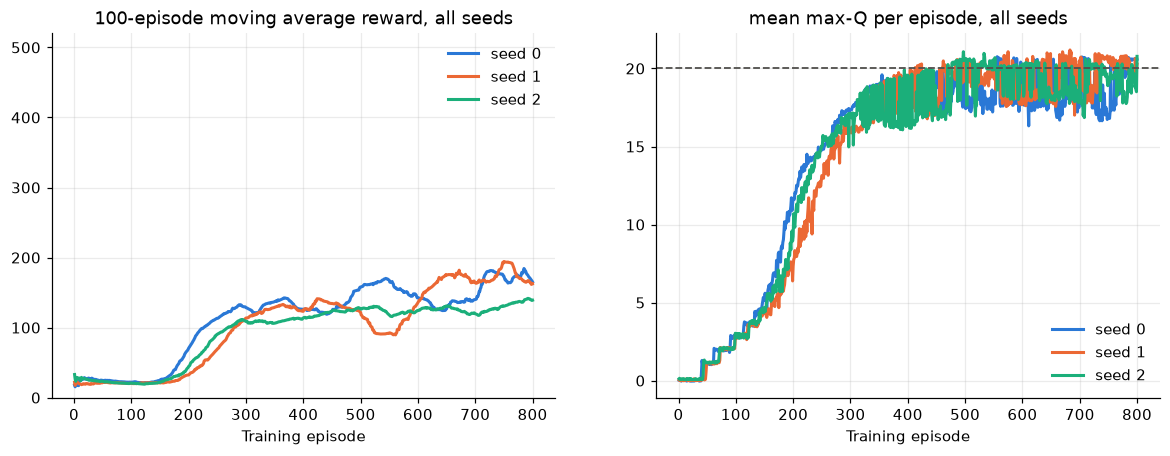

In [15]:
plot_training(results[0]["hist"]["reward"], "CartPole-v1 DQN: episode reward and 100-episode moving average (seed 0)",
              os.path.join(OUT, "training_seed0.png"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for seed, color in zip(SEEDS, [BLUE, ORANGE, AQUA]):
    h = results[seed]["hist"]; ep = np.arange(1, len(h["reward"]) + 1)
    axes[0].plot(ep, moving_average(h["reward"]), color=color, lw=2, label=f"seed {seed}")
    axes[1].plot(ep, h["max_q"], color=color, lw=2, label=f"seed {seed}")
axes[0].set_ylim(0, 520); axes[0].set_title("100-episode moving average reward, all seeds")
axes[1].axhline(Q_CEILING, color=GRAY, ls="--", lw=1.2); axes[1].set_title("mean max-Q per episode, all seeds")
for ax in axes:
    ax.set_xlabel("Training episode"); ax.legend(frameon=False)
fig.savefig(os.path.join(OUT, "all_seeds.png"), dpi=150, bbox_inches="tight")
plt.show()

## Plot (iii): 500 evaluation episodes

Greedy policy on environment seeds 900000+ (never used in training). The next cell picks the best snapshot of each seed on 20 validation episodes (seeds 800000+) and evaluates it on the same 500 test seeds.

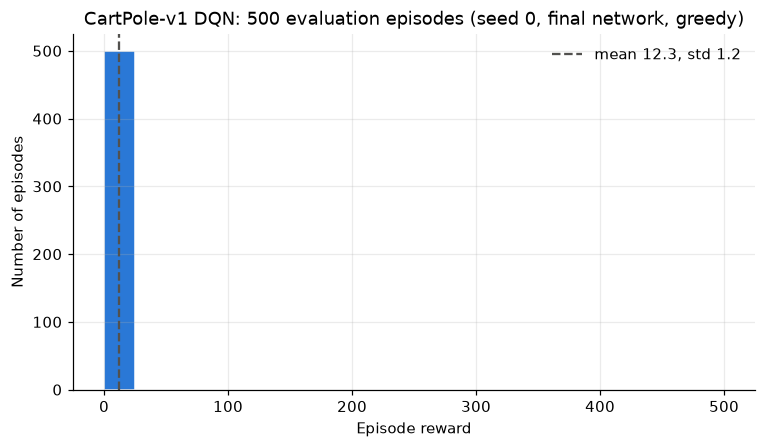

seed | FINAL network: mean ± std (share at 500) | BEST checkpoint: mean ± std (share at 500)
   0 |   12.3 ±   1.2 (0.00)                 |   15.9 ±   1.5 (0.00)
   1 |  134.4 ±   3.6 (0.00)                 |   85.7 ±   5.7 (0.00)
   2 |  178.4 ±  38.8 (0.00)                 |  124.2 ±   4.6 (0.00)


In [16]:
def play_episode(env, net, seed=None, eps=0.0, rng=None):
    rng = rng if rng is not None else np.random.default_rng(seed)
    s, _ = env.reset(seed=seed)
    total = 0.0
    while True:
        a = choose_action(q_of(net, s), eps, 2, rng)
        s, r, term, trunc, _ = env.step(a); total += r
        if term or trunc:
            return total


def evaluate(net, n=EVAL_EPISODES, eps=0.0, seed_offset=900_000):
    env = gym.make("CartPole-v1")
    scores = np.array([play_episode(env, net, seed=seed_offset + i, eps=eps) for i in range(n)])
    env.close()
    return scores


eval_scores, eval_best = {}, {}
for seed in SEEDS:
    eval_scores[seed] = evaluate(results[seed]["online"])
    best_net = QNet().to(DEVICE); best_net.load_state_dict(results[seed]["best_state"])
    eval_best[seed] = evaluate(best_net)

sc = eval_scores[0]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(sc, bins=np.arange(0, 525, 25), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(sc.mean(), color=GRAY, ls="--", lw=1.5, label=f"mean {sc.mean():.1f}, std {sc.std():.1f}")
ax.set_xlabel("Episode reward"); ax.set_ylabel("Number of episodes")
ax.set_title("CartPole-v1 DQN: 500 evaluation episodes (seed 0, final network, greedy)")
ax.legend(frameon=False)
fig.savefig(os.path.join(OUT, "eval_hist_seed0.png"), dpi=150, bbox_inches="tight")
plt.show()

print("seed | FINAL network: mean ± std (share at 500) | BEST checkpoint: mean ± std (share at 500)")
for seed in SEEDS:
    f_, b_ = eval_scores[seed], eval_best[seed]
    print(f"{seed:4d} | {f_.mean():6.1f} ± {f_.std():5.1f} ({np.mean(f_ == 500):.2f})                 "
          f"| {b_.mean():6.1f} ± {b_.std():5.1f} ({np.mean(b_ == 500):.2f})")
with open(os.path.join(OUT, "eval_scores.json"), "w") as f:
    json.dump({"final": {f"seed{s}": v.tolist() for s, v in eval_scores.items()},
               "best": {f"seed{s}": v.tolist() for s, v in eval_best.items()}}, f)

seed 0: snapshot from episode 475 (validation mean 329.3) | 500 test games: 329.4 ± 150.1, share at 500 = 0.36
seed 1: snapshot from episode 650 (validation mean 382.9) | 500 test games: 357.6 ± 154.9, share at 500 = 0.49
seed 2: snapshot from episode 625 (validation mean 248.2) | 500 test games: 237.5 ± 39.3, share at 500 = 0.00


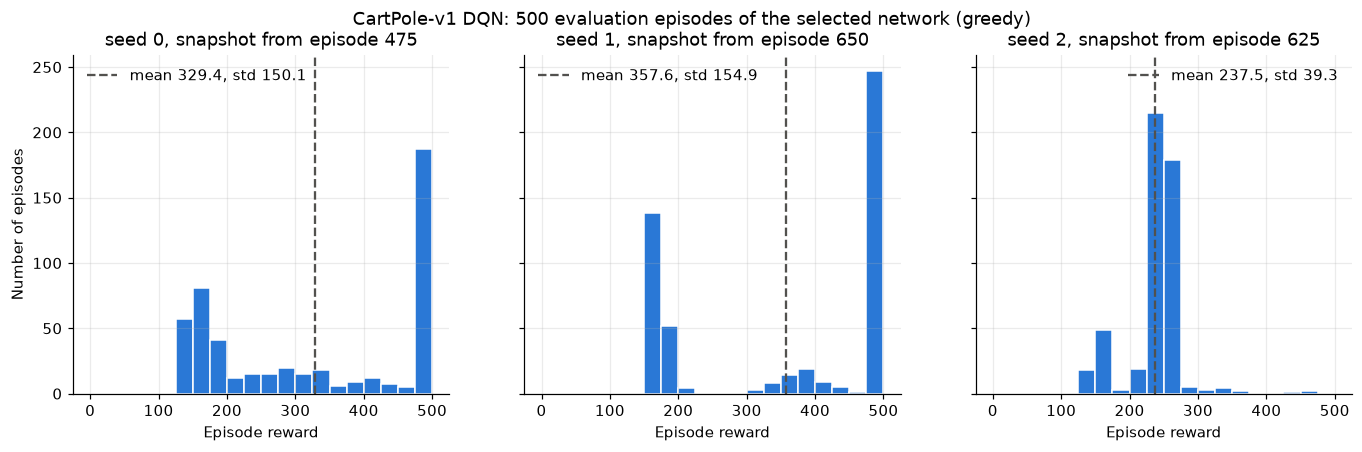

In [17]:
# best snapshot on validation seeds, then 500 test episodes
VAL_EPISODES = 20
selected, sel_scores, sel_ep = {}, {}, {}
for seed in SEEDS:
    best_ep, best_val = None, -1.0
    for ep, sd in sorted(results[seed]["snapshots"].items()):
        net = QNet().to(DEVICE); net.load_state_dict(sd); net.eval()
        val = evaluate(net, n=VAL_EPISODES, seed_offset=800_000).mean()   # validation seeds
        if val > best_val:
            best_ep, best_val = ep, val
    net = QNet().to(DEVICE); net.load_state_dict(results[seed]["snapshots"][best_ep]); net.eval()
    selected[seed], sel_ep[seed], sel_scores[seed] = net, best_ep, evaluate(net)   # 500 test games, seeds 900,000+
    torch.save(net.state_dict(), os.path.join(OUT, f"qnet_selected_seed{seed}.pt"))
    s = sel_scores[seed]
    print(f"seed {seed}: snapshot from episode {best_ep} (validation mean {best_val:.1f}) | "
          f"500 test games: {s.mean():.1f} ± {s.std():.1f}, share at 500 = {np.mean(s == 500):.2f}")

fig, axes = plt.subplots(1, len(SEEDS), figsize=(5 * len(SEEDS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, seed in zip(axes, SEEDS):
    s = sel_scores[seed]
    ax.hist(s, bins=np.arange(0, 525, 25), color=BLUE, edgecolor="white", linewidth=1)
    ax.axvline(s.mean(), color=GRAY, ls="--", lw=1.5, label=f"mean {s.mean():.1f}, std {s.std():.1f}")
    ax.set_title(f"seed {seed}, snapshot from episode {sel_ep[seed]}")
    ax.set_xlabel("Episode reward"); ax.legend(frameon=False)
axes[0].set_ylabel("Number of episodes")
fig.suptitle("CartPole-v1 DQN: 500 evaluation episodes of the selected network (greedy)")
fig.savefig(os.path.join(OUT, "eval_hist_selected.png"), dpi=150, bbox_inches="tight")
plt.show()
with open(os.path.join(OUT, "eval_selected.json"), "w") as f:
    json.dump({f"seed{s}": {"episode": int(sel_ep[s]), "scores": sel_scores[s].tolist()} for s in SEEDS}, f)

# Validation tests

## Test A: Q-values vs. the analytic ceiling

Expected: mean max-Q of the last 50 episodes within 0.85-1.1 x 20, and Q(0, 0, 0, 0) close to 20 for both actions.

In [20]:
print("seed | mean max-Q, last 50 episodes | ratio to 20 | Q(centre, left) | Q(centre, right)")
for seed in SEEDS:
    mq = float(np.mean(results[seed]["hist"]["max_q"][-50:]))
    qc = q_of(results[seed]["online"], np.zeros(4, np.float32))
    print(f"{seed:4d} | {mq:28.2f} | {mq / Q_CEILING:11.2f} | {qc[0]:15.2f} | {qc[1]:16.2f}")

seed | mean max-Q, last 50 episodes | ratio to 20 | Q(centre, left) | Q(centre, right)
   0 |                        19.52 |        0.98 |           20.49 |            20.59
   1 |                        20.26 |        1.01 |           20.56 |            20.67
   2 |                        19.17 |        0.96 |           20.77 |            20.76


## Test B: gamma = 0

Every target is r = 1, so Q should be about 1 in every state.

In [21]:
r0 = train(seed=0, tag="gamma0", gamma=0.0, n_episodes=150, warmup=200, stop_when_solved=False,
           snapshot_every=0, verbose=False, save=False)
with torch.no_grad():
    qs = r0["online"](torch.from_numpy(r0["buffer"].s[:len(r0["buffer"])]).to(DEVICE)).cpu().numpy()
print(f"gamma = 0: Q over {len(qs)} stored states: mean {qs.mean():.3f} | min {qs.min():.3f} | max {qs.max():.3f} "
      f"| largest |Q - 1| = {np.abs(qs - 1).max():.3f}")

gamma = 0: Q over 3699 stored states: mean 1.001 | min 0.986 | max 1.020 | largest |Q - 1| = 0.020


## Test C: chain MDP vs. value iteration

7-state chain, gamma = 0.9, reward 0.3 at the left end and 1.0 at the right end, 50-step limit. Q* comes from value iteration (HW1). Expected: |Q_DQN - Q*| < 0.1 and the same greedy actions.

In [22]:
class ChainEnv:
    def __init__(self, n=7, start=3, r_left=0.3, r_right=1.0, max_steps=50):
        self.n, self.start, self.r_left, self.r_right, self.max_steps = n, start, r_left, r_right, max_steps
        self.s, self.t = start, 0

    def _obs(self):
        o = np.zeros(self.n, np.float32); o[self.s] = 1.0
        return o

    def reset(self, seed=None):
        self.s, self.t = self.start, 0
        return self._obs(), {}

    def step(self, a):
        self.s += 1 if a == 1 else -1; self.t += 1
        r = self.r_left if self.s == 0 else (self.r_right if self.s == self.n - 1 else 0.0)
        terminated = self.s in (0, self.n - 1)
        truncated = (not terminated) and self.t >= self.max_steps
        return self._obs(), r, terminated, truncated, {}

    def close(self):
        pass


def chain_tables(env):
    """R[a, s] and P[a, s, s'] for the chain; the two ends are absorbing with zero reward (= terminal)."""
    n = env.n; R = np.zeros((2, n)); P = np.zeros((2, n, n))
    for s in range(n):
        for a in (0, 1):
            if s in (0, n - 1):
                P[a, s, s] = 1.0
                continue
            s2 = s + (1 if a == 1 else -1)
            P[a, s, s2] = 1.0
            R[a, s] = env.r_left if s2 == 0 else (env.r_right if s2 == n - 1 else 0.0)
    return R, P


def value_iteration_max(R, P, gamma, tol=1e-10):
    """HW1's value iteration, with rewards (max) instead of costs (min). Returns Q*[a, s] and V*[s]."""
    V = np.zeros(R.shape[1])
    while True:
        Q = R + gamma * (P @ V)
        V_new = Q.max(axis=0)
        if np.max(np.abs(V_new - V)) < tol:
            return Q, V_new
        V = V_new


CHAIN_GAMMA = 0.9
chain = ChainEnv()
Q_star, V_star = value_iteration_max(*chain_tables(chain), CHAIN_GAMMA)
rc = train(seed=0, tag="chain", make_env=ChainEnv, obs_dim=chain.n, n_actions=2, gamma=CHAIN_GAMMA,
           warmup=200, target_sync=100, n_episodes=800,
           eps_schedule=lambda step: epsilon_at(step, 1.0, 0.3, 1500),      # keep visiting all states
           stop_when_solved=False, snapshot_every=0, verbose=False, save=False)
with torch.no_grad():
    Q_dqn = rc["online"](torch.eye(chain.n, device=DEVICE)).cpu().numpy()   # row s = Q(s, left), Q(s, right)
print("state | Q*(left) Q*(right) | DQN(left) DQN(right) | best move: VI / DQN")
errs = []
for s in range(1, chain.n - 1):
    errs.append(float(np.abs(Q_dqn[s] - Q_star[:, s]).max()))
    print(f"{s:5d} | {Q_star[0, s]:8.3f} {Q_star[1, s]:9.3f} | {Q_dqn[s, 0]:9.3f} {Q_dqn[s, 1]:10.3f} "
          f"| {'LR'[int(Q_star[:, s].argmax())]} / {'LR'[int(Q_dqn[s].argmax())]}")
print(f"largest |Q_DQN - Q*| over non-terminal states: {max(errs):.3f}   (prediction: < 0.1, identical best moves)")

state | Q*(left) Q*(right) | DQN(left) DQN(right) | best move: VI / DQN
    1 |    0.300     0.656 |     0.300      0.656 | R / R
    2 |    0.590     0.729 |     0.590      0.729 | R / R
    3 |    0.656     0.810 |     0.656      0.810 | R / R
    4 |    0.729     0.900 |     0.729      0.900 | R / R
    5 |    0.810     1.000 |     0.810      1.000 | R / R
largest |Q_DQN - Q*| over non-terminal states: 0.000   (prediction: < 0.1, identical best moves)


## Test D: ablations

Same `train()` with one part removed: no target network (copied every step), no replay (buffer and batch of 1), cut-off treated as termination. Expected: the first two do not learn.

Ablation: full DQN
Ablation: no target network
Ablation: no replay buffer
Ablation: cut-off treated as failure

variant                    | episodes | best 100-avg | first episode with 100-avg >= 475 | mean max-Q (last 50) | peak Q ever
full DQN                   |      250 |        113.3 | None                              |                13.74 |       16.16
no target network          |      250 |         22.5 | None                              |            675301.54 |  1821248.12
no replay buffer           |      250 |         24.4 | None                              |                 9.98 |       11.90
cut-off treated as failure |      250 |        113.3 | None                              |                13.74 |       16.16


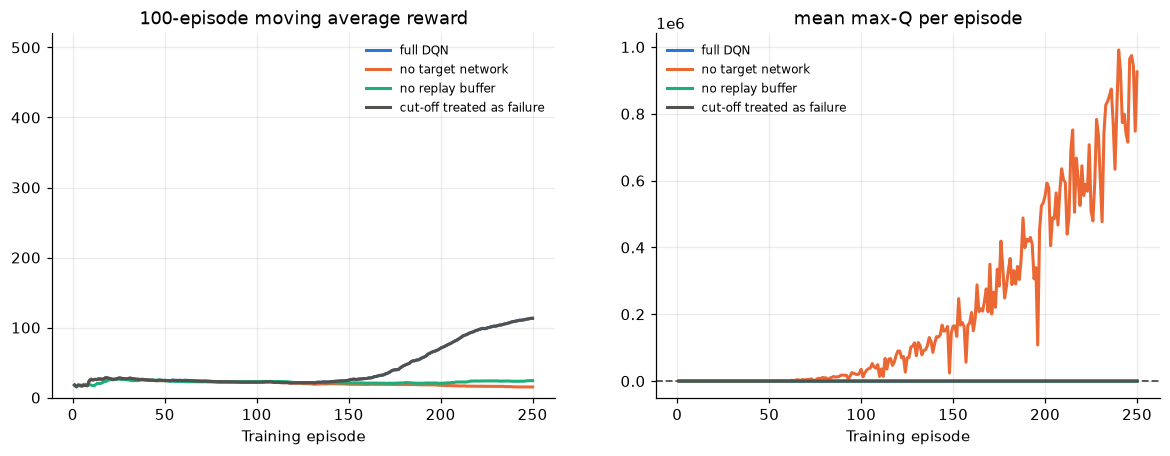

In [23]:
ABLATIONS = {
    "full DQN": {},
    "no target network": {"target_sync": 1},
    "no replay buffer": {"buffer_size": 1, "batch_size": 1, "warmup": 1},
    "cut-off treated as failure": {"handle_truncation": False},
}
abl = {}
for name, kw in ABLATIONS.items():
    print(f"Ablation: {name}")
    abl[name] = train(seed=0, tag="abl_" + name.replace(" ", "_"), n_episodes=250, snapshot_every=0, verbose=False, save=False, **kw)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
print("\nvariant                    | episodes | best 100-avg | first episode with 100-avg >= 475 | mean max-Q (last 50) | peak Q ever")
for (name, res), color in zip(abl.items(), [BLUE, ORANGE, AQUA, GRAY]):
    h = res["hist"]; ep = np.arange(1, len(h["reward"]) + 1); ma = moving_average(h["reward"])
    hit = next((i + 1 for i in range(99, len(ma)) if ma[i] >= SOLVED_AVG), None)
    axes[0].plot(ep, ma, color=color, lw=2, label=name); axes[1].plot(ep, h["max_q"], color=color, lw=2, label=name)
    print(f"{name:26s} | {len(ep):8d} | {res['best_ma']:12.1f} | {str(hit):33s} | {np.mean(h['max_q'][-50:]):20.2f} | {max(h['peak_q']):11.2f}")
axes[0].set_ylim(0, 520); axes[0].set_title("100-episode moving average reward"); axes[0].set_xlabel("Training episode")
axes[1].axhline(Q_CEILING, color=GRAY, ls="--", lw=1.2); axes[1].set_title("mean max-Q per episode"); axes[1].set_xlabel("Training episode")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
fig.savefig(os.path.join(OUT, "ablations.png"), dpi=150, bbox_inches="tight")
plt.show()

## Test E: fit a fixed batch

With the target network frozen, the loss on one batch should drop by more than 100x.

In [24]:
torch.manual_seed(0); rng = np.random.default_rng(0)
online, target = QNet().to(DEVICE), QNet().to(DEVICE); sync_target(online, target)
opt = torch.optim.Adam(online.parameters(), lr=LR)
small = ReplayBuffer(64, 4); env = gym.make("CartPole-v1"); s, _ = env.reset(seed=0)
while len(small) < 64:
    a = int(rng.integers(2)); s2, r, term, trunc, _ = env.step(a); small.add(s, a, r, s2, term); s = s2
    if term or trunc:
        s, _ = env.reset()
env.close()
fixed = tuple(torch.from_numpy(x[:64]) for x in (small.s, small.a, small.r, small.s2, small.done))
losses = [dqn_update(online, target, opt, fixed, GAMMA, loss_fn="mse", grad_clip=None)[0] for _ in range(500)]
print(f"MSE loss on a fixed batch: step 1 {losses[0]:.4f} | step 100 {losses[99]:.6f} | step 500 {losses[-1]:.2e} "
      f"| ratio {losses[0] / max(losses[-1], 1e-12):.0f}x")

MSE loss on a fixed batch: step 1 1.1215 | step 100 0.000342 | step 500 3.72e-05 | ratio 30129x


## Test F: reproducibility

Two CPU runs with the same seed should give identical results.

In [25]:
_saved_device = DEVICE
DEVICE = torch.device("cpu")
ra = train(seed=5, tag="det", n_episodes=40, warmup=200, stop_when_solved=False, snapshot_every=0, verbose=False, save=False)
rb = train(seed=5, tag="det", n_episodes=40, warmup=200, stop_when_solved=False, snapshot_every=0, verbose=False, save=False)
DEVICE = _saved_device
print("identical reward sequences:", ra["hist"]["reward"] == rb["hist"]["reward"])
print("identical max-Q sequences: ", np.allclose(ra["hist"]["max_q"], rb["hist"]["max_q"]))

identical reward sequences: True
identical max-Q sequences:  True


## Test G: calibration

Predicted Q(s_t, a_t) vs. realized discounted return-to-go over 20 greedy episodes (a time-limit cut-off is bootstrapped with 1/(1 - gamma)).

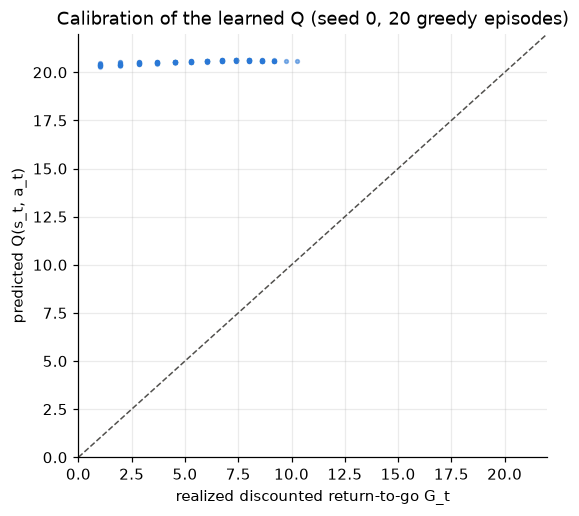

235 steps | mean |Q - G| = 15.16 | correlation 0.888 | mean Q 20.54 | mean G 5.38


In [26]:
def discounted_returns(rewards, gamma, truncated=False):
    G = np.zeros(len(rewards), dtype=np.float32)
    running = (1.0 / (1.0 - gamma)) if truncated else 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        G[t] = running
    return G


env = gym.make("CartPole-v1"); net = results[0]["online"]
pred, real = [], []
for i in range(20):
    s, _ = env.reset(seed=950_000 + i); qs_, rs_ = [], []
    while True:
        q = q_of(net, s); a = int(np.argmax(q)); qs_.append(q[a])
        s, r, term, trunc, _ = env.step(a); rs_.append(r)
        if term or trunc:
            break
    pred += qs_; real += list(discounted_returns(rs_, GAMMA, truncated=trunc and not term))
env.close()
pred, real = np.array(pred), np.array(real)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(real, pred, s=6, alpha=0.3, color=BLUE)
ax.plot([0, 22], [0, 22], color=GRAY, ls="--", lw=1); ax.set_xlim(0, 22); ax.set_ylim(0, 22)
ax.set_xlabel("realized discounted return-to-go G_t"); ax.set_ylabel("predicted Q(s_t, a_t)")
ax.set_title("Calibration of the learned Q (seed 0, 20 greedy episodes)")
fig.savefig(os.path.join(OUT, "calibration.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"{len(pred)} steps | mean |Q - G| = {np.abs(pred - real).mean():.2f} | correlation {np.corrcoef(pred, real)[0, 1]:.3f} "
      f"| mean Q {pred.mean():.2f} | mean G {real.mean():.2f}")

# Non-standard plot: decision boundary and value map

Policy (blue = left, orange = right) and max-Q over pole angle x angular velocity, cart at rest, at snapshots taken during training. Physics suggests a diagonal boundary (push toward the lean). The second cell saves `decision_boundary.gif`.

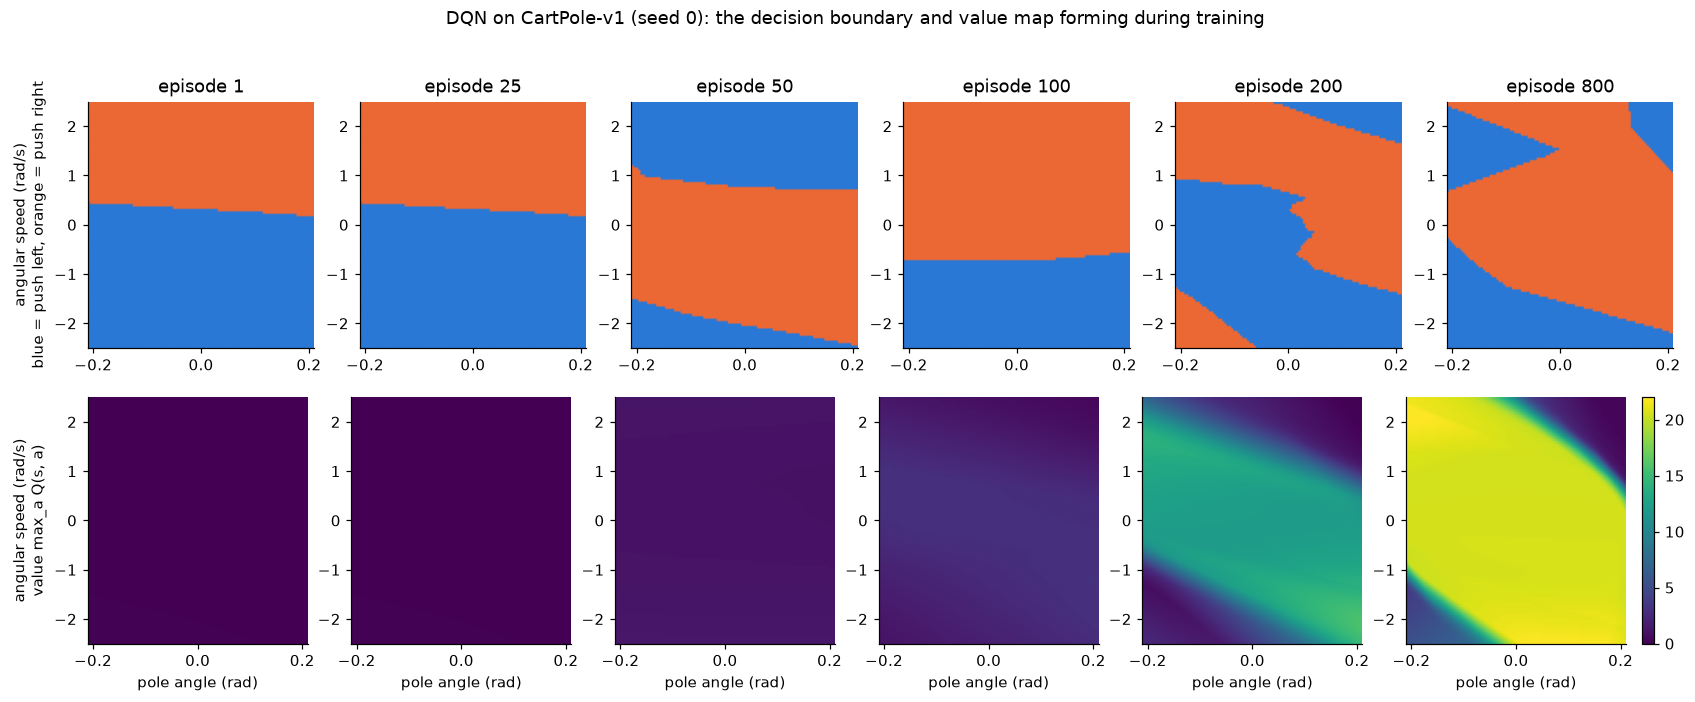

In [27]:
def q_grid(state_dict, n=101, theta_lim=0.21, omega_lim=2.5):
    net = QNet().to(DEVICE); net.load_state_dict(state_dict); net.eval()
    th = np.linspace(-theta_lim, theta_lim, n); om = np.linspace(-omega_lim, omega_lim, n)
    TH, OM = np.meshgrid(th, om)
    states = np.stack([np.zeros(TH.size), np.zeros(TH.size), TH.ravel(), OM.ravel()], 1).astype(np.float32)
    with torch.no_grad():
        q = net(torch.from_numpy(states).to(DEVICE)).cpu().numpy()
    return th, om, q[:, 0].reshape(n, n), q[:, 1].reshape(n, n)


snaps = results[0]["snapshots"]; snap_eps = sorted(snaps)
grids = {e: q_grid(snaps[e]) for e in snap_eps}
pick = sorted(set([e for e in snap_eps if e in (1, 25, 50, 100, 200)] + [snap_eps[-1]]))
extent = [grids[pick[0]][0][0], grids[pick[0]][0][-1], grids[pick[0]][1][0], grids[pick[0]][1][-1]]
policy_cmap = ListedColormap([BLUE, ORANGE])

fig, axes = plt.subplots(2, len(pick), figsize=(3.1 * len(pick), 6.4), squeeze=False)
for j, e in enumerate(pick):
    th, om, qL, qR = grids[e]
    axes[0, j].imshow((qR > qL).astype(float), origin="lower", extent=extent, aspect="auto", cmap=policy_cmap, vmin=0, vmax=1)
    axes[0, j].set_title(f"episode {e}")
    im = axes[1, j].imshow(np.maximum(qL, qR), origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0, vmax=Q_CEILING * 1.1)
    for ax in axes[:, j]:
        ax.grid(False)
    axes[1, j].set_xlabel("pole angle (rad)")
axes[0, 0].set_ylabel("angular speed (rad/s)\nblue = push left, orange = push right")
axes[1, 0].set_ylabel("angular speed (rad/s)\nvalue max_a Q(s, a)")
fig.colorbar(im, ax=axes[1, :].tolist(), fraction=0.02, pad=0.01)
fig.suptitle("DQN on CartPole-v1 (seed 0): the decision boundary and value map forming during training", y=1.01)
fig.savefig(os.path.join(OUT, "decision_boundary_snapshots.png"), dpi=150, bbox_inches="tight")
plt.show()

In [28]:
try:
    from matplotlib.animation import FuncAnimation, PillowWriter
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.5, 3.8))

    def draw(i):
        e = snap_eps[i]; th, om, qL, qR = grids[e]
        a1.clear(); a2.clear()
        a1.imshow((qR > qL).astype(float), origin="lower", extent=extent, aspect="auto", cmap=policy_cmap, vmin=0, vmax=1)
        a2.imshow(np.maximum(qL, qR), origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0, vmax=Q_CEILING * 1.1)
        a1.set_title(f"policy (blue = left, orange = right), episode {e}", fontsize=9)
        a2.set_title(f"value max_a Q, episode {e}", fontsize=9)
        for ax in (a1, a2):
            ax.set_xlabel("pole angle (rad)"); ax.grid(False)
        a1.set_ylabel("angular speed (rad/s)")

    anim = FuncAnimation(fig, draw, frames=len(snap_eps))
    gif_path = os.path.join(OUT, "decision_boundary.gif")
    anim.save(gif_path, writer=PillowWriter(fps=3)); plt.close(fig)
    print("Saved", gif_path, f"({len(snap_eps)} frames)")
except Exception as exc:          # GIF is optional
    print("GIF not written:", exc)

Saved ./rl_hw2_cartpole/decision_boundary.gif (33 frames)
